In [1]:
import os
import random
import scipy.io
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm
from HybridKANSRF import HybridColorKAN



In [2]:
number_of_primitives = 3
visible_range = False#Use False to select entire spectrum
include_shadows = True
no_of_epochs = 30
#Visible range of pavia dataset has 66 bands and full spectrum has 103 bands
no_of_bands = 66 if visible_range else 103
output_classes = 9 if include_shadows else 8

In [3]:
hsi = scipy.io.loadmat("PaviaU.mat")
image = hsi["paviaU"]

gt = scipy.io.loadmat("PaviaU_gt.mat")
index = gt["paviaU_gt"]
image  =image[:, :, :no_of_bands]

print(image.shape)
print(index.shape)

(610, 340, 103)
(610, 340)


In [4]:
#Normalizing the image
max_val = np.max(image)
normalized_image = image.astype(np.float32) / max_val

In [5]:

image_for_training = normalized_image[:,:,:no_of_bands]
print(image_for_training.shape)

(610, 340, 103)


In [6]:
x = []
for i in range(len(image_for_training)):
    for j in range(len(image_for_training[0])):
        if (index[i][j] == 0) or (index[i][j] == 9 and (not include_shadows)): #Ignoring all unclassified pixels
            continue
        x.append(image_for_training[i][j])

x = np.asarray(x,dtype=np.float32)
print(x.shape)

(42776, 103)


In [7]:
y = []

for i in range(len(image)):
    for j in range(len(image[0])):
        if index[i][j] == 0 or \
           (index[i][j] == 9 and (not include_shadows)):
            continue

        y.append(index[i][j]-1)

y = np.asarray(y , dtype=np.int64)
y.shape

(42776,)

In [8]:
wavelengths = torch.linspace(
    430, 860, 103,
    dtype=torch.float32
)

In [9]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", device)


model = HybridColorKAN(
    no_of_bands=no_of_bands,
    number_of_primitives=number_of_primitives,
    output_classes=output_classes,
    wavelengths=wavelengths,
    # RBF bases used to generate the smooth wavelength SRF
    wavelength_num_grids=12,

    # Original FastKAN intensity RBF bases
    intensity_num_grids=8,

    # First experiment:
    # signed smooth wavelength envelope
    nonnegative_srf=False,

    # Keep original FastKAN base path
    use_base_update=True,

    # Same initialization scale as original FastKAN
    spline_weight_init_scale=0.1
).to(device)

print(model)

Using device: cpu
HybridColorKAN(
  (primitives): ModuleList(
    (0-2): 3 x HybridSpectralPrimitive(
      (srf_generator): WavelengthSRFGenerator(
        (wavelength_rbf): GaussianRBF()
      )
      (layernorm): LayerNorm((103,), eps=1e-05, elementwise_affine=True)
      (intensity_rbf): GaussianRBF()
      (spline_linear): SplineLinear(in_features=824, out_features=1, bias=False)
      (base_linear): Linear(in_features=103, out_features=1, bias=True)
    )
  )
  (classifier_dense): Linear(in_features=3, out_features=9, bias=True)
)


In [10]:
print("Bands:", no_of_bands)
print("Wavelength count:", len(wavelengths))
print(
    "Wavelength range:",
    wavelengths.min().item(),
    "to",
    wavelengths.max().item(),
    "nm"
)

assert len(wavelengths) == no_of_bands

with torch.no_grad():
    test_input = torch.randn(2, no_of_bands, device=device)
    test_output = model(test_input)

print("Test output shape:", test_output.shape)

Bands: 103
Wavelength count: 103
Wavelength range: 430.0 to 860.0 nm
Test output shape: torch.Size([2, 9])


In [11]:
from torchinfo import summary
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

model = model.to(device)

summary(
    model,
    input_size=(1, no_of_bands))

optimizer = torch.optim.Adam(
    model.parameters(),)

criterion = nn.CrossEntropyLoss()

x_tensor = torch.tensor( x,dtype=torch.float32)

y_tensor = torch.tensor( y,dtype=torch.long)

batch_size = 32

dataset = TensorDataset(x_tensor,y_tensor)

train_loader = DataLoader(dataset,batch_size=batch_size,shuffle=True)

loss_history = []
accuracy_history = []

for epoch in range(no_of_epochs):

    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        optimizer.zero_grad()

        output = model(batch_x)

        loss = criterion(output,batch_y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * batch_x.size(0)

        predictions = torch.argmax(output,dim=1)

        total_correct += ( predictions == batch_y).sum().item()

        total_samples += batch_y.size(0)

    epoch_loss = total_loss / total_samples

    epoch_accuracy = (total_correct / total_samples
    )

    loss_history.append(
        epoch_loss
    )

    accuracy_history.append(
        epoch_accuracy
    )

    print(
        f"Epoch [{epoch+1}/{no_of_epochs}] | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.4f}"
    )

Using device: cpu


Epoch [1/30] | Loss: 1.1029 | Accuracy: 0.5933
Epoch [2/30] | Loss: 0.6765 | Accuracy: 0.7388
Epoch [3/30] | Loss: 0.5823 | Accuracy: 0.7686
Epoch [4/30] | Loss: 0.5257 | Accuracy: 0.7881
Epoch [5/30] | Loss: 0.4841 | Accuracy: 0.8130
Epoch [6/30] | Loss: 0.4507 | Accuracy: 0.8333
Epoch [7/30] | Loss: 0.4244 | Accuracy: 0.8477
Epoch [8/30] | Loss: 0.4026 | Accuracy: 0.8567
Epoch [9/30] | Loss: 0.3855 | Accuracy: 0.8643
Epoch [10/30] | Loss: 0.3725 | Accuracy: 0.8696
Epoch [11/30] | Loss: 0.3613 | Accuracy: 0.8725
Epoch [12/30] | Loss: 0.3528 | Accuracy: 0.8762
Epoch [13/30] | Loss: 0.3441 | Accuracy: 0.8793
Epoch [14/30] | Loss: 0.3372 | Accuracy: 0.8830
Epoch [15/30] | Loss: 0.3311 | Accuracy: 0.8849
Epoch [16/30] | Loss: 0.3250 | Accuracy: 0.8868
Epoch [17/30] | Loss: 0.3200 | Accuracy: 0.8899
Epoch [18/30] | Loss: 0.3152 | Accuracy: 0.8911
Epoch [19/30] | Loss: 0.3110 | Accuracy: 0.8910
Epoch [20/30] | Loss: 0.3075 | Accuracy: 0.8939
Epoch [21/30] | Loss: 0.3032 | Accuracy: 0.8949
E

In [12]:
for i, primitive in enumerate(model.primitives):
    srf = primitive.get_srf().detach()

    print(
        f"Primitive {i + 1}:",
        "min =", srf.min().item(),
        "max =", srf.max().item(),
        "L2 norm =", torch.norm(srf).item()
    )

Primitive 1: min = -0.15217091143131256 max = 0.06379570066928864 L2 norm = 1.0
Primitive 2: min = -0.09871894866228104 max = 0.21299433708190918 L2 norm = 1.0
Primitive 3: min = -0.17573870718479156 max = 0.1997925192117691 L2 norm = 0.9999998807907104


In [13]:
for i, primitive in enumerate(model.primitives):
    generator = primitive.srf_generator

    print(f"\nPrimitive {i + 1}")
    print("RBF coefficients:", generator.rbf_coefficients.detach().cpu().numpy())
    print("Base coefficient:", generator.base_coefficient.item())
    print("SRF offset:", generator.srf_offset.item())
    print("Wavelength range:",
          generator.wavelength_positions.min().item(),
          "to",
          generator.wavelength_positions.max().item())


Primitive 1
RBF coefficients: [-0.01404994 -0.02381528 -0.15454693  0.6609526  -0.18225755 -0.11842723
  0.11081158 -0.32638168 -0.12041164 -0.23057462  0.02754014 -0.09038594]
Base coefficient: -0.16505619883537292
SRF offset: -0.2789258360862732
Wavelength range: 430.0 to 860.0

Primitive 2
RBF coefficients: [ 0.1362953   0.00651802  0.24610971  0.0395685   0.12320977  0.11835454
  0.01398969  0.30093583 -0.12451345  0.7790583  -0.25677714 -0.25480813]
Base coefficient: -0.03837805986404419
SRF offset: 0.058197565376758575
Wavelength range: 430.0 to 860.0

Primitive 3
RBF coefficients: [-0.3259923   0.27054146 -0.2536974  -0.07335415 -0.18230756  0.00409795
 -0.12998119 -0.32499322  0.28859225  0.5312742  -0.13982745 -0.4324236 ]
Base coefficient: -0.018038809299468994
SRF offset: -0.0254252590239048
Wavelength range: 430.0 to 860.0


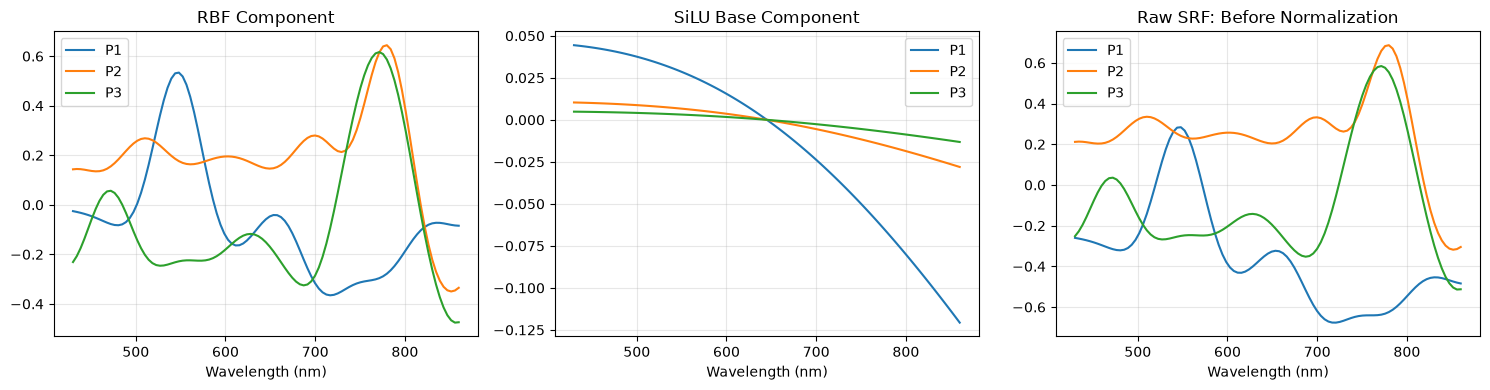

In [14]:
import matplotlib.pyplot as plt

model.eval()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

wavelength_np = (
    model.primitives[0]
    .srf_generator.wavelength_positions
    .detach()
    .cpu()
    .numpy()
)

for i, primitive in enumerate(model.primitives):

    generator = primitive.srf_generator

    with torch.no_grad():

        wavelength_basis = generator.wavelength_rbf(
            generator.wavelength_positions
        )

        rbf_component = (
            wavelength_basis @ generator.rbf_coefficients
        )

        wavelength_min = generator.wavelength_positions.min()
        wavelength_max = generator.wavelength_positions.max()

        midpoint = (wavelength_min + wavelength_max) / 2
        half_range = (wavelength_max - wavelength_min) / 2

        z = (
            generator.wavelength_positions - midpoint
        ) / half_range.clamp_min(1e-8)

        base_component = (
            generator.base_coefficient * torch.nn.functional.silu(z)
        )

        raw_srf = generator.get_raw_srf()

    axes[0].plot(wavelength_np, rbf_component.cpu().numpy(), label=f"P{i+1}")
    axes[1].plot(wavelength_np, base_component.cpu().numpy(), label=f"P{i+1}")
    axes[2].plot(wavelength_np, raw_srf.cpu().numpy(), label=f"P{i+1}")

axes[0].set_title("RBF Component")
axes[1].set_title("SiLU Base Component")
axes[2].set_title("Raw SRF: Before Normalization")

for ax in axes:
    ax.set_xlabel("Wavelength (nm)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

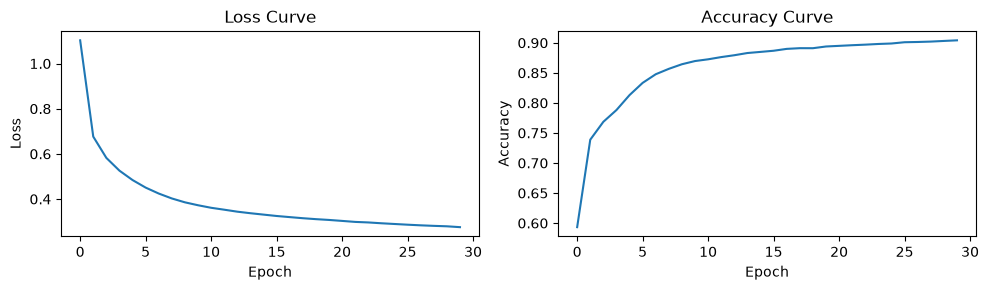

In [15]:
plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.plot(loss_history)
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(accuracy_history)
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.tight_layout()
plt.show()

In [16]:
wavelength_np = wavelengths.cpu().numpy()

Primitive 1 SRF shape: (103,)


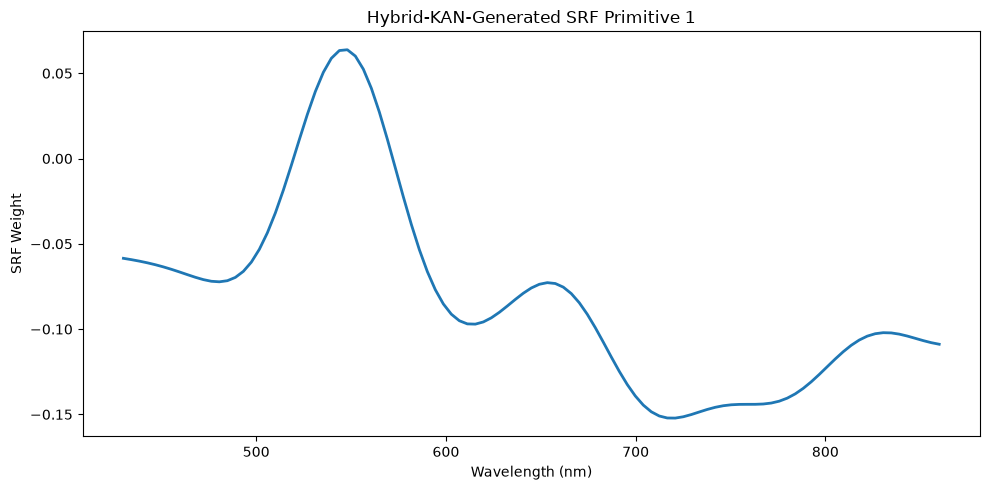

Primitive 2 SRF shape: (103,)


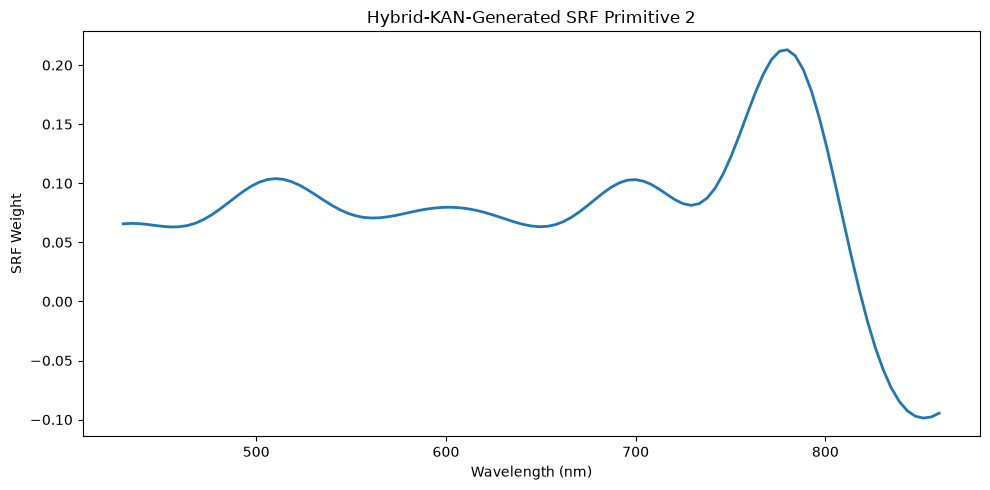

Primitive 3 SRF shape: (103,)


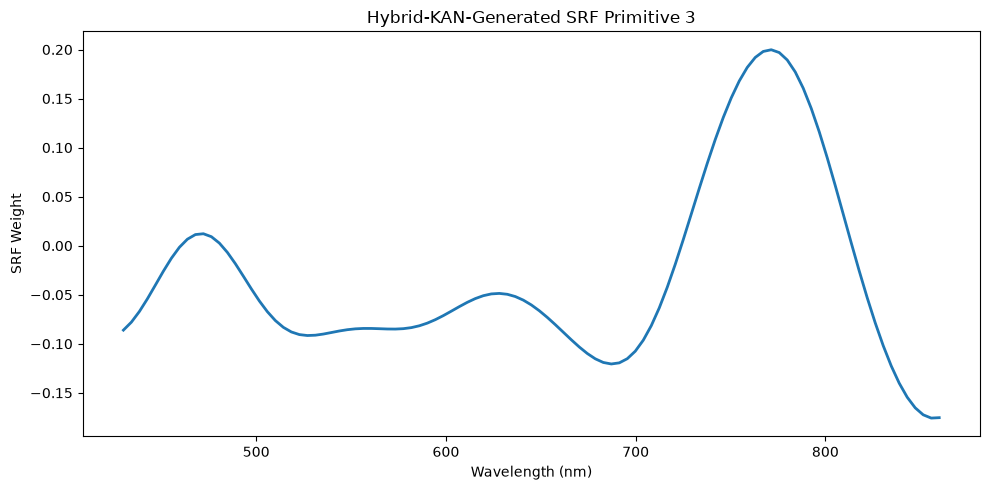

In [17]:
primitive_curves = []

model.eval()

for primitive_no in range(number_of_primitives):

    with torch.no_grad():

        curve = (
            model.primitives[primitive_no]
            .get_srf()
            .cpu()
            .numpy()
        )

    primitive_curves.append(curve)

    print(
        f"Primitive {primitive_no + 1} "
        f"SRF shape: {curve.shape}"
    )

    plt.figure(figsize=(10, 5))

    plt.plot(
        wavelength_np,
        curve,
        linewidth=2
    )

    plt.title(
        f"Hybrid-KAN-Generated SRF "
        f"Primitive {primitive_no + 1}"
    )

    plt.xlabel("Wavelength (nm)")
    plt.ylabel("SRF Weight")
    plt.tight_layout()
    plt.show()

In [18]:
for i ,p in enumerate(primitive_curves):
    print(i+1, f"primitive_{i+1}" , p[0])

1 primitive_1 -0.05849743
2 primitive_2 0.06566949
3 primitive_3 -0.086069


In [19]:

for i, (name, parameter) in enumerate(model.named_parameters()):
    if parameter.requires_grad:
        print(i, name, parameter.shape)

0 primitives.0.srf_generator.rbf_coefficients torch.Size([12])
1 primitives.0.srf_generator.base_coefficient torch.Size([1])
2 primitives.0.srf_generator.srf_offset torch.Size([1])
3 primitives.0.layernorm.weight torch.Size([103])
4 primitives.0.layernorm.bias torch.Size([103])
5 primitives.0.spline_linear.weight torch.Size([1, 824])
6 primitives.0.base_linear.weight torch.Size([1, 103])
7 primitives.0.base_linear.bias torch.Size([1])
8 primitives.1.srf_generator.rbf_coefficients torch.Size([12])
9 primitives.1.srf_generator.base_coefficient torch.Size([1])
10 primitives.1.srf_generator.srf_offset torch.Size([1])
11 primitives.1.layernorm.weight torch.Size([103])
12 primitives.1.layernorm.bias torch.Size([103])
13 primitives.1.spline_linear.weight torch.Size([1, 824])
14 primitives.1.base_linear.weight torch.Size([1, 103])
15 primitives.1.base_linear.bias torch.Size([1])
16 primitives.2.srf_generator.rbf_coefficients torch.Size([12])
17 primitives.2.srf_generator.base_coefficient torch

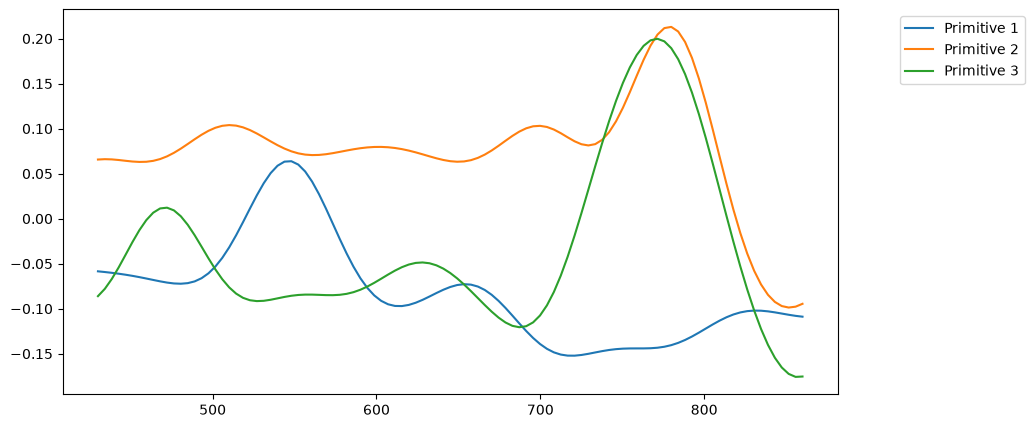

In [20]:

plt.figure(figsize=(10, 5))

for primitive_no in range(number_of_primitives):

    plt.plot(wavelength_np,primitive_curves[primitive_no],label=f"Primitive {primitive_no + 1}")
plt.legend(bbox_to_anchor=(1.25, 1))
plt.show()




In [21]:
model.eval()

for k, primitive in enumerate(model.primitives):

    with torch.no_grad():
        weights = primitive.get_srf().detach().cpu().numpy()

    print(f"\nPrimitive {k + 1}")
    print(f"Total weights: {len(weights)}")

    for band, (wavelength, weight) in enumerate(
        zip(wavelength_np, weights), start=1
    ):
        print(
            f"Band {band:3d} | "
            f"Wavelength: {wavelength:.1f} nm | "
            f"Weight: {weight:.6f}"
        )


Primitive 1
Total weights: 103
Band   1 | Wavelength: 430.0 nm | Weight: -0.058497
Band   2 | Wavelength: 434.2 nm | Weight: -0.059278
Band   3 | Wavelength: 438.4 nm | Weight: -0.060151
Band   4 | Wavelength: 442.6 nm | Weight: -0.061138
Band   5 | Wavelength: 446.9 nm | Weight: -0.062260
Band   6 | Wavelength: 451.1 nm | Weight: -0.063528
Band   7 | Wavelength: 455.3 nm | Weight: -0.064941
Band   8 | Wavelength: 459.5 nm | Weight: -0.066474
Band   9 | Wavelength: 463.7 nm | Weight: -0.068068
Band  10 | Wavelength: 467.9 nm | Weight: -0.069623
Band  11 | Wavelength: 472.2 nm | Weight: -0.070988
Band  12 | Wavelength: 476.4 nm | Weight: -0.071956
Band  13 | Wavelength: 480.6 nm | Weight: -0.072268
Band  14 | Wavelength: 484.8 nm | Weight: -0.071620
Band  15 | Wavelength: 489.0 nm | Weight: -0.069685
Band  16 | Wavelength: 493.2 nm | Weight: -0.066139
Band  17 | Wavelength: 497.5 nm | Weight: -0.060705
Band  18 | Wavelength: 501.7 nm | Weight: -0.053193
Band  19 | Wavelength: 505.9 nm 

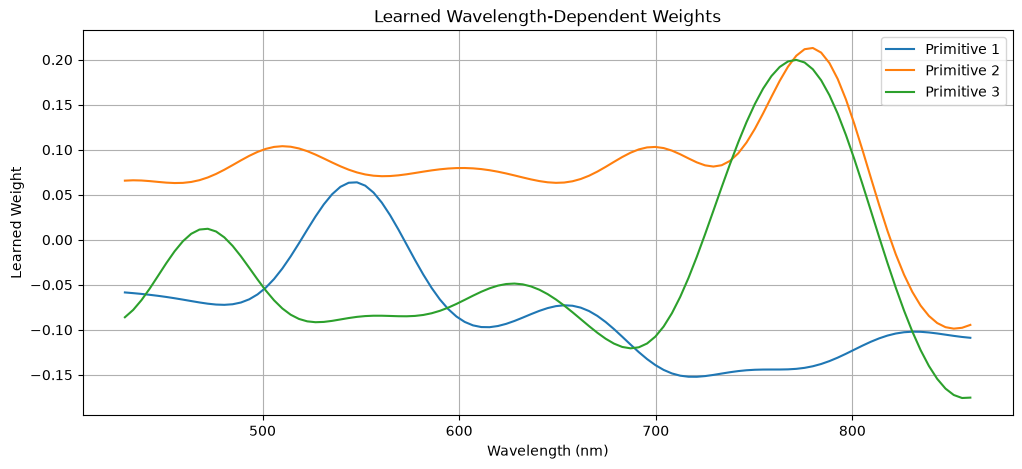

In [22]:
wavelength_np = wavelengths.detach().cpu().numpy()

model.eval()

plt.figure(figsize=(12, 5))

for k, primitive in enumerate(model.primitives):
    with torch.no_grad():
        weights = primitive.get_srf().detach().cpu().numpy()

    plt.plot(
        wavelength_np,
        weights,
        label=f"Primitive {k + 1}"
    )

plt.xlabel("Wavelength (nm)")
plt.ylabel("Learned Weight")
plt.title("Learned Wavelength-Dependent Weights")
plt.legend()
plt.grid(True)
plt.show()

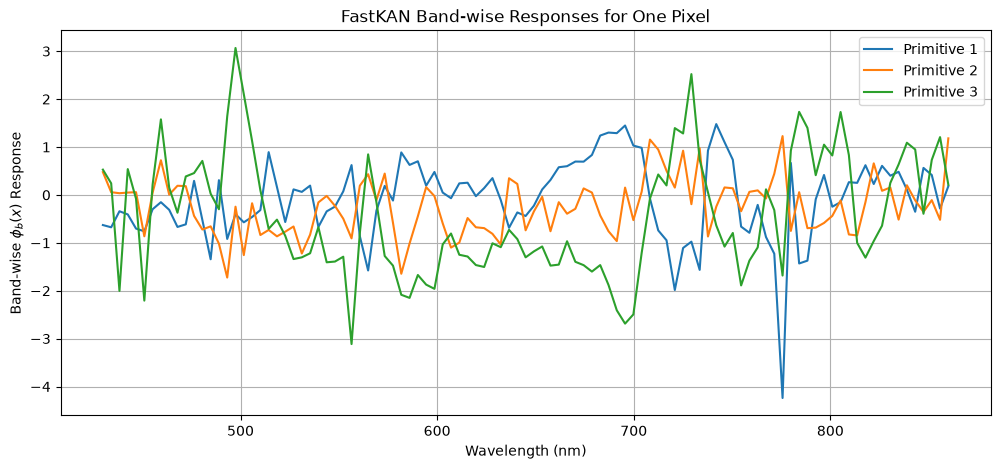

In [23]:
# Select one representative pixel from the image
pixel = torch.tensor(
    image_for_training[100, 100],
    dtype=torch.float32,
    device=device
).unsqueeze(0)

model.eval()

plt.figure(figsize=(12, 5))

with torch.no_grad():
    for k, primitive in enumerate(model.primitives):

        # Shape: (1, 1, 103) when using 103 bands
        phi = primitive.get_band_contributions(pixel)

        # One response value per band
        phi = phi[0, 0, :].cpu().numpy()

        plt.plot(
            wavelength_np,
            phi,
            label=f"Primitive {k + 1}"
        )

plt.xlabel("Wavelength (nm)")
plt.ylabel(r"Band-wise $\phi_b(x)$ Response")
plt.title(r"FastKAN Band-wise Responses for One Pixel")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
model_name = (
    f'{no_of_bands}bands_'f'{number_of_primitives}primitives_' f'{"with_shadow" if include_shadows else "without_shadow"}_' f'fastkan_random_init')
print(model_name)

103bands_3primitives_with_shadow_fastkan_random_init


In [25]:
print(model_name)

103bands_3primitives_with_shadow_fastkan_random_init


In [26]:
torch.save(model.state_dict(), f"{model_name}.pth")

In [27]:
model = HybridColorKAN(
    no_of_bands=no_of_bands,
    number_of_primitives=number_of_primitives,
    output_classes=output_classes,
    wavelengths= wavelengths,

    # Same values used while training
    wavelength_num_grids=12,
    intensity_num_grids=8,
    nonnegative_srf=False,
    use_base_update=True,
    spline_weight_init_scale=0.1
).to(device)


model.load_state_dict(
    torch.load(
        f"{model_name}.pth",
        weights_only=True
    )
)

model.eval()

HybridColorKAN(
  (primitives): ModuleList(
    (0-2): 3 x HybridSpectralPrimitive(
      (srf_generator): WavelengthSRFGenerator(
        (wavelength_rbf): GaussianRBF()
      )
      (layernorm): LayerNorm((103,), eps=1e-05, elementwise_affine=True)
      (intensity_rbf): GaussianRBF()
      (spline_linear): SplineLinear(in_features=824, out_features=1, bias=False)
      (base_linear): Linear(in_features=103, out_features=1, bias=True)
    )
  )
  (classifier_dense): Linear(in_features=3, out_features=9, bias=True)
)

In [28]:
def predict_image():
    x_pred = image_for_training.reshape(-1, no_of_bands)

    print("Prediction Input Shape:", x_pred.shape)
    print("Predicting...")

    x_pred = torch.tensor( x_pred,dtype=torch.float32, device=device)

    model.eval()

    with torch.no_grad():

        primitive_outputs = [primtive(x_pred) for primtive in model.primitives]
        prediction = torch.cat(primitive_outputs,dim=1)

    predicted_image = prediction.cpu().numpy().reshape(
        image.shape[0],
        image.shape[1],
        number_of_primitives
    )

    return predicted_image
def normalize_images(predicted_image, channels):

    global_min = np.min(predicted_image)
    global_max = np.max(predicted_image)

    global_minmax_image = (
        (predicted_image - global_min) /
        (global_max - global_min + 1e-8)
    )
    channel_minmax_image = np.zeros_like(
        predicted_image,
        dtype=np.float32
    )

    for i in range(predicted_image.shape[-1]):

        channel = predicted_image[:, :, i]

        channel_min = np.min(channel)
        channel_max = np.max(channel)

        channel_minmax_image[:, :, i] = (
            (channel - channel_min) /
            (channel_max - channel_min + 1e-8)
        )
    clipped_image = np.clip(
        predicted_image,
        0,
        1
    )
    c1, c2, c3 = [channel - 1 for channel in channels]

    rgb_global_minmax = np.dstack((
        global_minmax_image[:, :, c1],
        global_minmax_image[:, :, c2],
        global_minmax_image[:, :, c3]
    ))

    rgb_channelwise = np.dstack((
        channel_minmax_image[:, :, c1],
        channel_minmax_image[:, :, c2],
        channel_minmax_image[:, :, c3]
    ))

    rgb_clipped = np.dstack((
        clipped_image[:, :, c1],
        clipped_image[:, :, c2],
        clipped_image[:, :, c3]
    ))

    return [
        rgb_global_minmax,
        rgb_channelwise,
        rgb_clipped
    ]


Prediction Input Shape: (207400, 103)
Predicting...


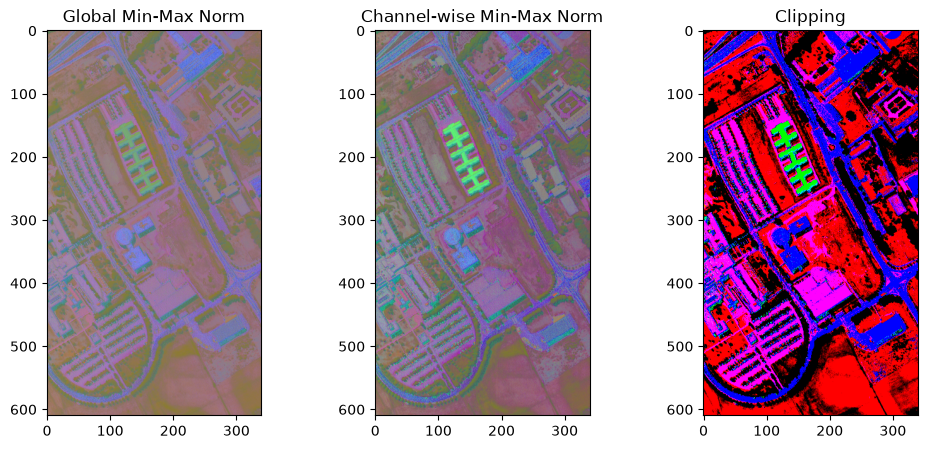

In [29]:
channels = [1, 2, 3]

predicted_image = predict_image()

normalized_images = normalize_images(
    predicted_image,
    channels
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(normalized_images[0])
plt.title("Global Min-Max Norm")

plt.subplot(1, 3, 2)
plt.imshow(normalized_images[1])
plt.title("Channel-wise Min-Max Norm")

plt.subplot(1, 3, 3)
plt.imshow(normalized_images[2])
plt.title("Clipping")

plt.show()